In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Kütüphaneler başarıyla yüklendi!")


Kütüphaneler başarıyla yüklendi!


In [16]:

# Rastgele sayı üreticimizi hazırlıyoruz
np.random.seed(42)

# 300 kişinin günlük çay tüketimi
cay = np.random.randint(0, 9, 300)

# 300 kişinin günlük kahve tüketimi
kahve = np.random.randint(0, 8, 300)

# Uyku süresini örnek bir ilişkiyle oluşturuyoruz
uyku = (
    8
    - (cay * 0.07)
    - (kahve * 0.22)
    + np.random.normal(0, 0.65, 300)
)

# Uyku süresini 4 ile 10 saat arasında tutuyoruz
uyku = np.clip(uyku, 4, 10)

# Verileri tabloya dönüştürüyoruz
veri = pd.DataFrame({
    "cay_fincani": cay,
    "kahve_fincani": kahve,
    "uyku_suresi": np.round(uyku, 2)
})

# CSV dosyasını oluşturuyoruz
veri.to_csv("uyku_verileri.csv", index=False)

print("Veri setimiz başarıyla oluşturuldu!")


Veri setimiz başarıyla oluşturuldu!


In [17]:

# İlk 5 satırı görüntüle
print("İlk 5 veri:")
display(veri.head())

# Veri setindeki toplam satır ve sütun sayısı
print("Veri setinin boyutu:")
print(veri.shape)

# Sütun bilgilerini görüntüle
print("Veri seti bilgileri:")
veri.info()

# Sayısal verilerin özetini görüntüle
print("İstatistiksel özet:")
display(veri.describe())


İlk 5 veri:


,cay_fincani,kahve_fincani,uyku_suresi
0,6,1,8.09
1,3,0,9.18
2,7,7,5.75
3,4,0,7.88
4,6,0,7.79


Veri setinin boyutu:
(300, 3)
Veri seti bilgileri:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   cay_fincani    300 non-null    int64  
 1   kahve_fincani  300 non-null    int64  
 2   uyku_suresi    300 non-null    float64
dtypes: float64(1), int64(2)
memory usage: 7.2 KB
İstatistiksel özet:


,cay_fincani,kahve_fincani,uyku_suresi
count,300.00000,300.000000,300.000000
mean,3.92000,3.436667,6.994500
std,2.64896,2.318889,0.877718
min,0.00000,0.000000,4.520000
25%,2.00000,1.000000,6.387500
50%,4.00000,3.000000,6.960000
75%,6.00000,5.000000,7.665000
max,8.00000,7.000000,9.930000


In [18]:

veri_sozlugu = pd.DataFrame({
    "Sutun_Adi": [
        "cay_fincani",
        "kahve_fincani",
        "uyku_suresi"
    ],
    "Veri_Tipi": [
        "Sayısal",
        "Sayısal",
        "Sayısal"
    ],
    "Aciklama": [
        "Günlük tüketilen çay bardağı sayısı",
        "Günlük tüketilen kahve fincanı sayısı",
        "Günlük uyku süresi (saat)"
    ]
})

display(veri_sozlugu)



,Sutun_Adi,Veri_Tipi,Aciklama
0,cay_fincani,Sayısal,Günlük tüketilen çay bardağı sayısı
1,kahve_fincani,Sayısal,Günlük tüketilen kahve fincanı sayısı
2,uyku_suresi,Sayısal,Günlük uyku süresi (saat)


In [19]:

# CSV dosyamızı tekrar okuyalım
veri = pd.read_csv("uyku_verileri.csv")

print("CSV dosyası başarıyla okundu!")

display(veri.head())


CSV dosyası başarıyla okundu!


,cay_fincani,kahve_fincani,uyku_suresi
0,6,1,8.09
1,3,0,9.18
2,7,7,5.75
3,4,0,7.88
4,6,0,7.79


In [20]:

# Her sütundaki eksik değer sayısını bulalım
print("Eksik veri sayıları:")

print(veri.isnull().sum())

# Toplam eksik veri sayısını bulalım
print("Toplam eksik veri:")

print(veri.isnull().sum().sum())


Eksik veri sayıları:
cay_fincani      0
kahve_fincani    0
uyku_suresi      0
dtype: int64
Toplam eksik veri:
0


In [21]:

# Tekrarlanan satırları kontrol edelim
print("Tekrarlanan satır sayısı:")
print(veri.duplicated().sum())

# Veri türlerini kontrol edelim
print("\nVeri türleri:")
print(veri.dtypes)

# Değer aralıklarını kontrol edelim
print("\nMinimum değerler:")
print(veri.min())

print("\nMaksimum değerler:")
print(veri.max())


Tekrarlanan satır sayısı:
4

Veri türleri:
cay_fincani        int64
kahve_fincani      int64
uyku_suresi      float64
dtype: object

Minimum değerler:
cay_fincani      0.00
kahve_fincani    0.00
uyku_suresi      4.52
dtype: float64

Maksimum değerler:
cay_fincani      8.00
kahve_fincani    7.00
uyku_suresi      9.93
dtype: float64


In [23]:

# Eksik verileri temizleyelim
veri = veri.dropna()

# Tekrarlanan satırları temizleyelim
veri = veri.drop_duplicates()

# Mantıksız değerleri kontrol edelim
veri = veri[
    (veri["cay_fincani"] >= 0) &
    (veri["kahve_fincani"] >= 0) &
    (veri["uyku_suresi"] >= 0) &
    (veri["uyku_suresi"] <= 24)
]

print("Veri temizleme işlemi tamamlandı!")

print("Güncel veri boyutu:", veri.shape)

# Temizlenmiş veriyi kaydedelim
veri.to_csv("temizlenmis_uyku_verileri.csv", index=False)


Veri temizleme işlemi tamamlandı!
Güncel veri boyutu: (296, 3)


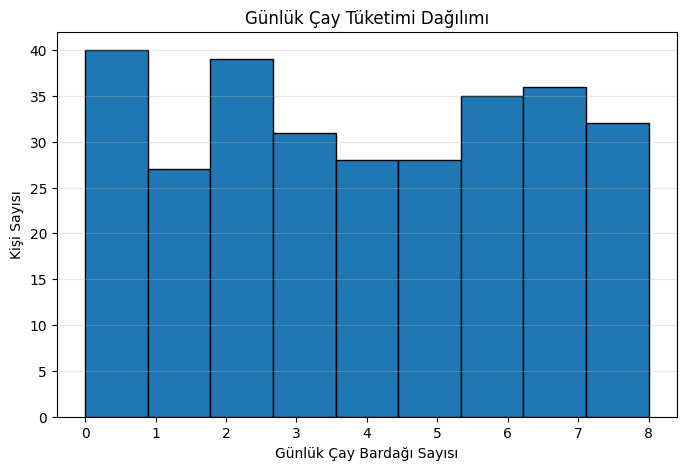

In [24]:

plt.figure(figsize=(8, 5))

plt.hist(veri["cay_fincani"], bins=9, edgecolor="black")

plt.title("Günlük Çay Tüketimi Dağılımı")
plt.xlabel("Günlük Çay Bardağı Sayısı")
plt.ylabel("Kişi Sayısı")

plt.grid(axis="y", alpha=0.3)
plt.show()



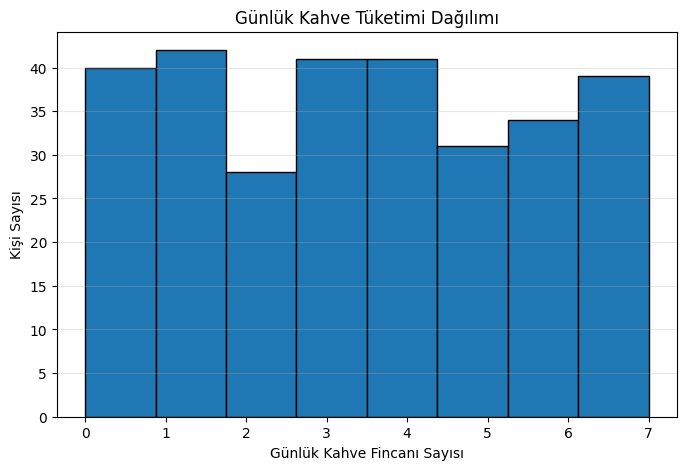

In [25]:

plt.figure(figsize=(8, 5))

plt.hist(veri["kahve_fincani"], bins=8, edgecolor="black")

plt.title("Günlük Kahve Tüketimi Dağılımı")
plt.xlabel("Günlük Kahve Fincanı Sayısı")
plt.ylabel("Kişi Sayısı")

plt.grid(axis="y", alpha=0.3)
plt.show()


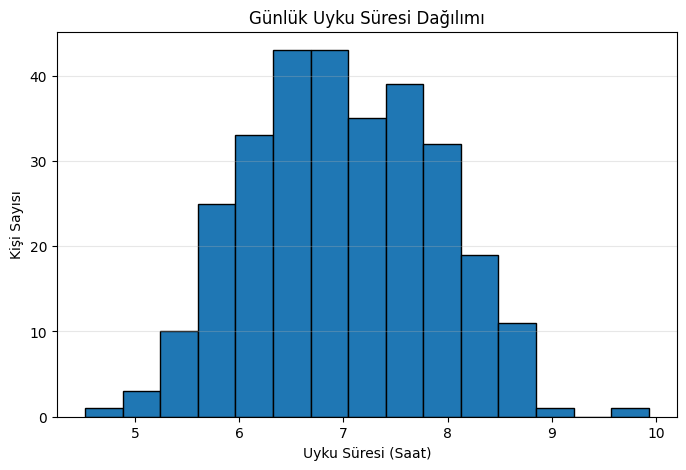

In [26]:

plt.figure(figsize=(8, 5))

plt.hist(veri["uyku_suresi"], bins=15, edgecolor="black")

plt.title("Günlük Uyku Süresi Dağılımı")
plt.xlabel("Uyku Süresi (Saat)")
plt.ylabel("Kişi Sayısı")

plt.grid(axis="y", alpha=0.3)
plt.show()


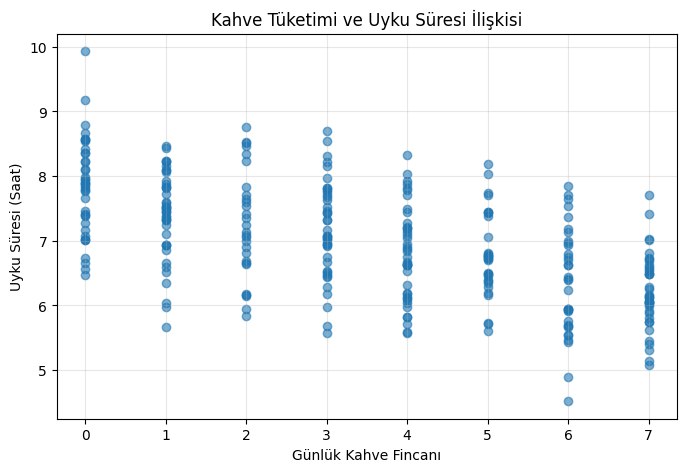

In [27]:

plt.figure(figsize=(8, 5))

plt.scatter(
    veri["kahve_fincani"],
    veri["uyku_suresi"],
    alpha=0.6
)

plt.title("Kahve Tüketimi ve Uyku Süresi İlişkisi")
plt.xlabel("Günlük Kahve Fincanı")
plt.ylabel("Uyku Süresi (Saat)")

plt.grid(alpha=0.3)
plt.show()



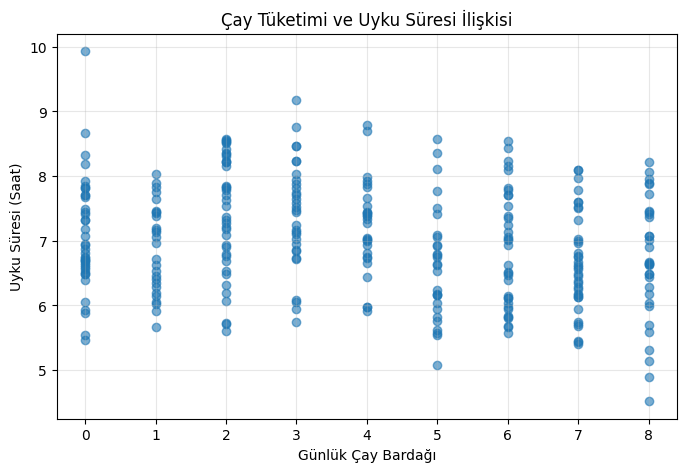

In [28]:

plt.figure(figsize=(8, 5))

plt.scatter(
    veri["cay_fincani"],
    veri["uyku_suresi"],
    alpha=0.6
)

plt.title("Çay Tüketimi ve Uyku Süresi İlişkisi")
plt.xlabel("Günlük Çay Bardağı")
plt.ylabel("Uyku Süresi (Saat)")

plt.grid(alpha=0.3)
plt.show()


Değişkenler arasındaki korelasyon:


,cay_fincani,kahve_fincani,uyku_suresi
cay_fincani,1.000000,-0.044012,-0.212411
kahve_fincani,-0.044012,1.000000,-0.582517
uyku_suresi,-0.212411,-0.582517,1.000000


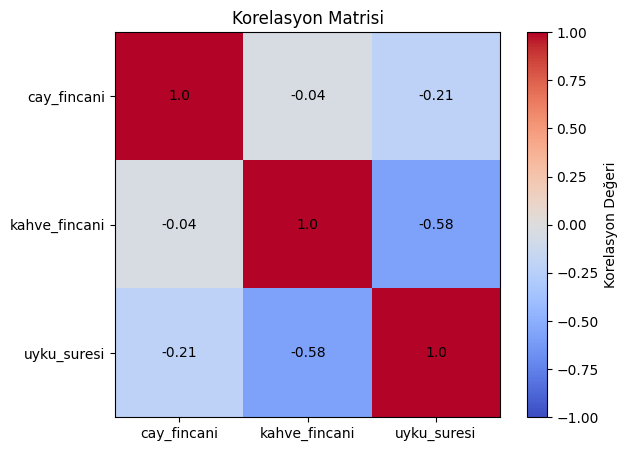

In [29]:

korelasyon = veri.corr()

print("Değişkenler arasındaki korelasyon:")
display(korelasyon)

plt.figure(figsize=(7, 5))

plt.imshow(korelasyon, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Korelasyon Değeri")

plt.xticks(range(len(korelasyon.columns)), korelasyon.columns)
plt.yticks(range(len(korelasyon.columns)), korelasyon.columns)

plt.title("Korelasyon Matrisi")

for i in range(len(korelasyon.columns)):
    for j in range(len(korelasyon.columns)):
        plt.text(
            j, i,
            round(korelasyon.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.show()


In [30]:

# Girdi değişkenlerimizi belirliyoruz
X = veri[["cay_fincani", "kahve_fincani"]]

# Tahmin etmek istediğimiz değişken
y = veri["uyku_suresi"]

print("Girdi değişkenleri (X):")
display(X.head())

print("Hedef değişken (y):")
display(y.head())


Girdi değişkenleri (X):


,cay_fincani,kahve_fincani
0,6,1
1,3,0
2,7,7
3,4,0
4,6,0


Hedef değişken (y):


,uyku_suresi
0,8.09
1,9.18
2,5.75
3,7.88
4,7.79


In [31]:

from sklearn.model_selection import train_test_split

# Verileri eğitim ve test olarak ayırıyoruz
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Eğitim verisi:", X_train.shape)
print("Test verisi:", X_test.shape)


Eğitim verisi: (236, 2)
Test verisi: (60, 2)


In [32]:

from sklearn.linear_model import LinearRegression

# Doğrusal regresyon modelimizi oluşturuyoruz
model = LinearRegression()

# Modelimizi eğitim verileriyle eğitiyoruz
model.fit(X_train, y_train)

print("Yapay zeka modelimiz başarıyla eğitildi!")


Yapay zeka modelimiz başarıyla eğitildi!


In [33]:
from sklearn.linear_model import LinearRegression

In [34]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Tahminleri yeniden hesaplayalım
tahminler = model.predict(X_test)

# Performans metriklerini hesaplayalım
mae = mean_absolute_error(y_test, tahminler)
mse = mean_squared_error(y_test, tahminler)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, tahminler)

# Sonuçları ekrana yazdıralım
print("MODEL PERFORMANS SONUÇLARI")
print("--------------------------")
print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Skoru:", round(r2, 3))


MODEL PERFORMANS SONUÇLARI
--------------------------
MAE: 0.516
MSE: 0.411
RMSE: 0.641
R2 Skoru: 0.346


In [35]:
!pip install gradio

In [36]:
import gradio as gr

print("Gradio başarıyla hazırlandı!")

Gradio başarıyla hazırlandı!


In [37]:
uygulama.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a09df56be06cb01a4a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [38]:
import joblib

joblib.dump(model, "uyku_tahmin_modeli.pkl")

print("Model başarıyla kaydedildi!")

Model başarıyla kaydedildi!


In [39]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [40]:
import os

proje_klasoru = "/content/drive/MyDrive/Cay_Kahve_Uyku_Tahmini"

os.makedirs(proje_klasoru, exist_ok=True)

print("Proje klasörü oluşturuldu!")

Proje klasörü oluşturuldu!


In [41]:
import joblib

model_yolu = os.path.join(
    proje_klasoru,
    "uyku_tahmin_modeli.pkl"
)

joblib.dump(model, model_yolu)

print("Yapay zeka modelimiz Drive'a kaydedildi!")

Yapay zeka modelimiz Drive'a kaydedildi!


In [42]:
veri_yolu = os.path.join(
    proje_klasoru,
    "temizlenmis_uyku_verileri.csv"
)

veri.to_csv(veri_yolu, index=False)

print("Temizlenmiş veri dosyamız Drive'a kaydedildi!")

Temizlenmiş veri dosyamız Drive'a kaydedildi!


In [43]:
print("Drive'daki proje dosyalarımız:")

for dosya in os.listdir(proje_klasoru):
    print(dosya)

Drive'daki proje dosyalarımız:
uyku_tahmin_modeli.pkl
temizlenmis_uyku_verileri.csv
gorev-planlayici
makine-derin öğrenme


In [44]:
def grafik_olustur():

    fig, eksenler = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Çay tüketimi ve uyku süresi
    eksenler[0].scatter(
        veri["cay_fincani"],
        veri["uyku_suresi"]
    )
    eksenler[0].set_title("Çay Tüketimi ve Uyku")
    eksenler[0].set_xlabel("Çay bardağı")
    eksenler[0].set_ylabel("Uyku süresi (saat)")

    # 2. Uyku süresi dağılımı
    eksenler[1].hist(
        veri["uyku_suresi"],
        bins=10
    )
    eksenler[1].set_title("Uyku Süresi Dağılımı")
    eksenler[1].set_xlabel("Uyku süresi (saat)")
    eksenler[1].set_ylabel("Kişi sayısı")

    # 3. Korelasyon grafiği
    korelasyon = veri.corr()

    goruntu = eksenler[2].imshow(
        korelasyon,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    eksenler[2].set_title("Değişkenler Arası Korelasyon")
    eksenler[2].set_xticks(range(3))
    eksenler[2].set_yticks(range(3))
    eksenler[2].set_xticklabels(["Çay", "Kahve", "Uyku"])
    eksenler[2].set_yticklabels(["Çay", "Kahve", "Uyku"])

    for i in range(3):
        for j in range(3):
            eksenler[2].text(
                j, i,
                round(korelasyon.iloc[i, j], 2),
                ha="center",
                va="center"
            )

    fig.colorbar(goruntu, ax=eksenler[2])

    plt.tight_layout()

    return fig

In [45]:
with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="orange",
        secondary_hue="slate"
    ),
    title="Çay ve Kahve Tüketimine Göre Uyku Tahmini"
) as uygulama:

    gr.Markdown("""
    # ☕ Çay ve Kahve Tüketimine Göre Uyku Tahmini

    Günlük çay ve kahve tüketiminizi girerek tahmini uyku sürenizi öğrenin.
    """)

    with gr.Row():

        with gr.Column():
            cay_girdisi = gr.Slider(
                0, 8, step=1, value=0,
                label="Günlük çay tüketimi (bardak)"
            )

            kahve_girdisi = gr.Slider(
                0, 7, step=1, value=0,
                label="Günlük kahve tüketimi (fincan)"
            )

            tahmin_butonu = gr.Button(
                "Tahmin Et",
                variant="primary"
            )

            temizle_butonu = gr.Button("Temizle")

        with gr.Column():
            sonuc = gr.Textbox(
                label="Tahmini Uyku Süresi",
                interactive=False
            )

    tahmin_butonu.click(
        fn=uyku_tahmini,
        inputs=[cay_girdisi, kahve_girdisi],
        outputs=sonuc
    )

    temizle_butonu.click(
        fn=lambda: (0, 0, ""),
        inputs=[],
        outputs=[cay_girdisi, kahve_girdisi, sonuc]
    )

    gr.Markdown("## 📊 Veri Analizi ve Grafikler")

    gr.Markdown(
        "Bu bölümde çay ve kahve tüketimi ile uyku süresi arasındaki ilişkileri inceleyebilirsiniz."
    )

    grafik_buton = gr.Button("Grafikleri Görüntüle")

    grafik_ciktisi = gr.Plot(label="Veri Analizi Grafikleri")

    grafik_buton.click(
        fn=grafik_olustur,
        inputs=[],
        outputs=grafik_ciktisi
    )

    gr.Markdown("""
    ---
    **Bilgilendirme:** Bu uygulama eğitim amacıyla oluşturulmuş
    yapay verilerle eğitilmiştir. Sonuçlar gerçek uyku ölçümü
    veya sağlık tavsiyesi değildir.
    """)

uygulama.launch(share=True)

/tmp/ipykernel_492/782658638.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7ad7312d76f0238219.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
